<a href="https://colab.research.google.com/github/fedesiboldim/proyecto-concurrente/blob/main/simulacion_game_of_life_unab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!nvidia-smi


Mon Oct 12 04:08:14 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   41C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
import numpy as np
import time
from numba import cuda

# 1. Kernel CUDA para el Juego de la Vida
@cuda.jit
def game_of_life_gpu(d_grid, d_next_grid, N):
    i, j = cuda.grid(2)

    # Manejo de bordes internos (1 a N-2)
    if 1 <= i < N - 1 and 1 <= j < N - 1:
        vecinos = (d_grid[i-1, j-1] + d_grid[i-1, j] + d_grid[i-1, j+1] +
                   d_grid[i,   j-1]                  + d_grid[i,   j+1] +
                   d_grid[i+1, j-1] + d_grid[i+1, j] + d_grid[i+1, j+1])

        if d_grid[i, j] == 1:
            d_next_grid[i, j] = 1 if (vecinos == 2 or vecinos == 3) else 0
        else:
            d_next_grid[i, j] = 1 if vecinos == 3 else 0

# 2. Configuración experimental
tamanos = [512, 1024, 2048]
generaciones = 10
block_dim = (16, 16)

print("=== HITO 2: BENCHMARK GPU (NVIDIA Tesla T4) ===")

for N in tamanos:
    # Matriz inicial aleatoria
    grid = np.random.choice([0, 1], size=(N, N), p=[0.8, 0.2]).astype(np.int32)
    grid_dim = ((N + block_dim[0] - 1) // block_dim[0], (N + block_dim[1] - 1) // block_dim[1])

    # Transferencia inicial CPU (Host) -> GPU (Device VRAM)
    d_grid = cuda.to_device(grid)
    d_next = cuda.device_array_like(d_grid)

    # Warmup (para compilar el kernel en tiempo de ejecución)
    game_of_life_gpu[grid_dim, block_dim](d_grid, d_next, N)
    cuda.synchronize()

    # Medición de las 10 generaciones en GPU
    t0 = time.time()
    for gen in range(generaciones):
        # Buffer-swapping para evitar race conditions
        if gen % 2 == 0:
            game_of_life_gpu[grid_dim, block_dim](d_grid, d_next, N)
        else:
            game_of_life_gpu[grid_dim, block_dim](d_next, d_grid, N)
    cuda.synchronize()
    t_gpu = time.time() - t0

    ms_por_gen = (t_gpu / generaciones) * 1000
    print(f"Grilla {N:4d}x{N:4d} | Tiempo GPU ({generaciones} gen): {t_gpu:.4f} s | Promedio: {ms_por_gen:.2f} ms/gen")

=== HITO 2: BENCHMARK GPU (NVIDIA Tesla T4) ===
Grilla  512x 512 | Tiempo GPU (10 gen): 0.0014 s | Promedio: 0.14 ms/gen
Grilla 1024x1024 | Tiempo GPU (10 gen): 0.0049 s | Promedio: 0.49 ms/gen
Grilla 2048x2048 | Tiempo GPU (10 gen): 0.0195 s | Promedio: 1.95 ms/gen


In [ ]:
import numpy as np
import time
from numba import cuda

# Dimensiones del bloque y tamaño de la baldosa con halo
TPB = 16  # Threads Per Block en cada dimension

# 1. Kernel optimizado con Shared Memory (Tiling)
@cuda.jit
def game_of_life_shared(d_grid, d_next_grid, N):
    # Baldosa de (16 + 2) x (16 + 2) para incluir el halo de 1 celda de vecinos
    s_tile = cuda.shared.array((18, 18), dtype=np.int32)

    tx = cuda.threadIdx.x
    ty = cuda.threadIdx.y
    bx = cuda.blockIdx.x
    by = cuda.blockIdx.y

    # Posicion global
    gx = bx * TPB + tx
    gy = by * TPB + ty

    # Coordenadas locales dentro de la baldosa compartida (1 a 16)
    lx = tx + 1
    ly = ty + 1

    # Cargar celda central
    if gx < N and gy < N:
        s_tile[ly, lx] = d_grid[gy, gx]
    else:
        s_tile[ly, lx] = 0

    # Cargar halos (bordes del tile) cooperativamente
    if tx == 0:
        s_tile[ly, 0] = d_grid[gy, gx - 1] if (gx > 0 and gy < N) else 0
    if tx == TPB - 1:
        s_tile[ly, 17] = d_grid[gy, gx + 1] if (gx + 1 < N and gy < N) else 0
    if ty == 0:
        s_tile[0, lx] = d_grid[gy - 1, gx] if (gy > 0 and gx < N) else 0
    if ty == TPB - 1:
        s_tile[17, lx] = d_grid[gy + 1, gx] if (gy + 1 < N and gx < N) else 0

    # Esquinas del halo
    if tx == 0 and ty == 0:
        s_tile[0, 0] = d_grid[gy - 1, gx - 1] if (gx > 0 and gy > 0) else 0
    if tx == TPB - 1 and ty == 0:
        s_tile[0, 17] = d_grid[gy - 1, gx + 1] if (gx + 1 < N and gy > 0) else 0
    if tx == 0 and ty == TPB - 1:
        s_tile[17, 0] = d_grid[gy + 1, gx - 1] if (gx > 0 and gy + 1 < N) else 0
    if tx == TPB - 1 and ty == TPB - 1:
        s_tile[17, 17] = d_grid[gy + 1, gx + 1] if (gx + 1 < N and gy + 1 < N) else 0

    # BARRERA DE SINCRONIZACIÓN: Asegurar que toda la baldosa esté cargada
    cuda.syncthreads()

    # Calcular estado consultando solo la Shared Memory ultrarrápida
    if 1 <= gx < N - 1 and 1 <= gy < N - 1:
        vecinos = (s_tile[ly - 1, lx - 1] + s_tile[ly - 1, lx] + s_tile[ly - 1, lx + 1] +
                   s_tile[ly,     lx - 1]                      + s_tile[ly,     lx + 1] +
                   s_tile[ly + 1, lx - 1] + s_tile[ly + 1, lx] + s_tile[ly + 1, lx + 1])

        if s_tile[ly, lx] == 1:
            d_next_grid[gy, gx] = 1 if (vecinos == 2 or vecinos == 3) else 0
        else:
            d_next_grid[gy, gx] = 1 if vecinos == 3 else 0

# --- EXPERIMENTO DE ESCALABILIDAD MASIVA (HITO 3) ---
tamanos = [1024, 2048, 4096, 8192]
generaciones = 10
block_dim = (TPB, TPB)

print("=== HITO 3: ESCALABILIDAD Y SHARED MEMORY (NVIDIA Tesla T4) ===")

for N in tamanos:
    grid = np.random.choice([0, 1], size=(N, N), p=[0.8, 0.2]).astype(np.int32)
    grid_dim = ((N + TPB - 1) // TPB, (N + TPB - 1) // TPB)

    d_grid = cuda.to_device(grid)
    d_next = cuda.device_array_like(d_grid)

    # Warmup
    game_of_life_shared[grid_dim, block_dim](d_grid, d_next, N)
    cuda.synchronize()

    t0 = time.time()
    for gen in range(generaciones):
        if gen % 2 == 0:
            game_of_life_shared[grid_dim, block_dim](d_grid, d_next, N)
        else:
            game_of_life_shared[grid_dim, block_dim](d_next, d_grid, N)
    cuda.synchronize()
    t_gpu = time.time() - t0

    ms_gen = (t_gpu / generaciones) * 1000
    celdas_total = N * N
    throughput_mcells = (celdas_total * generaciones / t_gpu) / 1e6

    print(f"Grilla {N:4d}x{N:4d} ({celdas_total/1e6:5.1f}M celdas) | Tiempo: {t_gpu:.4f} s | {ms_gen:6.2f} ms/gen | Throughput: {throughput_mcells:8.1f} MCells/s")

=== HITO 3: ESCALABILIDAD Y SHARED MEMORY (NVIDIA Tesla T4) ===
Grilla 1024x1024 (  1.0M celdas) | Tiempo: 0.0018 s |   0.18 ms/gen | Throughput:   5711.0 MCells/s
Grilla 2048x2048 (  4.2M celdas) | Tiempo: 0.0069 s |   0.69 ms/gen | Throughput:   6092.1 MCells/s
Grilla 4096x4096 ( 16.8M celdas) | Tiempo: 0.0271 s |   2.71 ms/gen | Throughput:   6186.1 MCells/s
Grilla 8192x8192 ( 67.1M celdas) | Tiempo: 0.1089 s |  10.89 ms/gen | Throughput:   6164.3 MCells/s


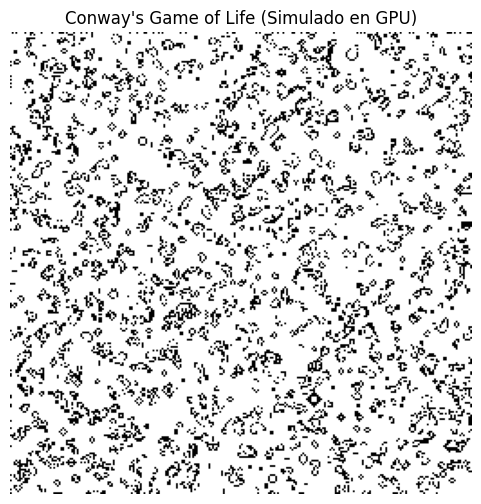

¡Imagen guardada como simulacion_game_of_life.png!


In [ ]:
import matplotlib.pyplot as plt

# Tomamos una muestra de la grilla de la GPU y la pasamos a CPU
matriz_resultado = d_grid.copy_to_host()

# Graficamos un recorte de 256x256 para que se vean bien las células
plt.figure(figsize=(6, 6))
plt.imshow(matriz_resultado[:256, :256], cmap='binary')
plt.title("Conway's Game of Life (Simulado en GPU)")
plt.axis('off')
plt.savefig("simulacion_game_of_life.png", bbox_inches='tight', dpi=150)
plt.show()
print("¡Imagen guardada como simulacion_game_of_life.png!")

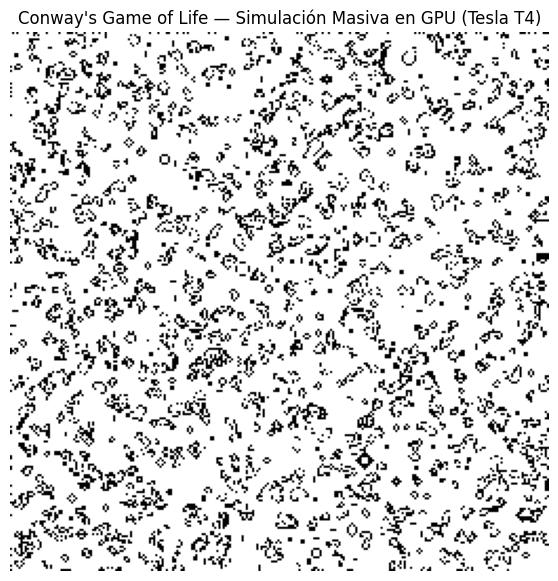

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import matplotlib.pyplot as plt
from google.colab import files

# Descargamos la grilla calculada por la GPU a memoria CPU
matriz_final = d_grid.copy_to_host()

# Generamos la figura con un recorte representativo
plt.figure(figsize=(7, 7))
plt.imshow(matriz_final[:256, :256], cmap='binary')
plt.title("Conway's Game of Life — Simulación Masiva en GPU (Tesla T4)", fontsize=12)
plt.axis('off')

# Guardamos el archivo y lo descargamos automáticamente a tu PC
plt.savefig("simulacion_game_of_life.png", bbox_inches='tight', dpi=200)
plt.show()

files.download("simulacion_game_of_life.png")